# TP N°4 : Extraction des primitives
Vision Artificielle – EMSI Casa

Placez l'image dans le dossier de travail sous le nom `image1.jpg`.

In [3]:
# !pip install opencv-python numpy matplotlib scikit-image
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

IMG_PATH = "snowmoon_kayn.jpg"

def show(images, titles, cols=3):
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(5 * cols, 4 * rows))
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(im, cmap="gray" if im.ndim == 2 else None)
        plt.title(t)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Détection de contours

### 1.1 Chargement et conversion en niveaux de gris

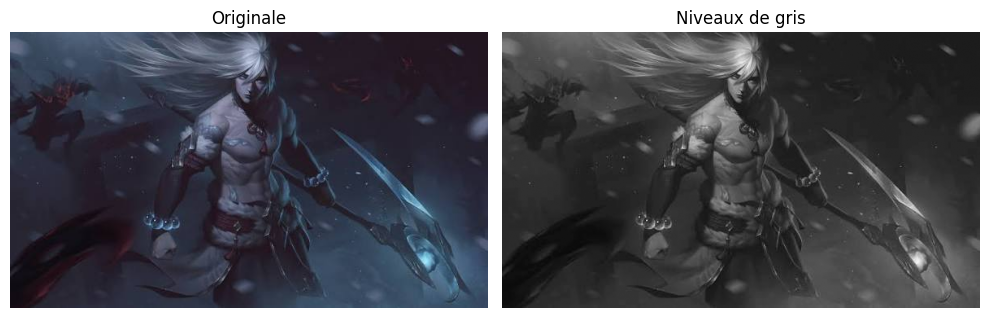

In [4]:
img = cv2.imread(IMG_PATH)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show([cv2.cvtColor(img, cv2.COLOR_BGR2RGB), gray], ["Originale", "Niveaux de gris"], cols=2)

### 1.2 Seuil binaire
Les pixels noirs (0) sont considérés comme arrière-plan et ignorés.

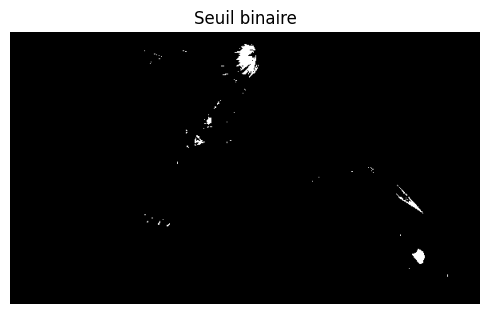

In [5]:
_, thresh = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)
show([thresh], ["Seuil binaire"], cols=1)

### 1.3 findContours() et drawContours()

Nombre de contours détectés : 75


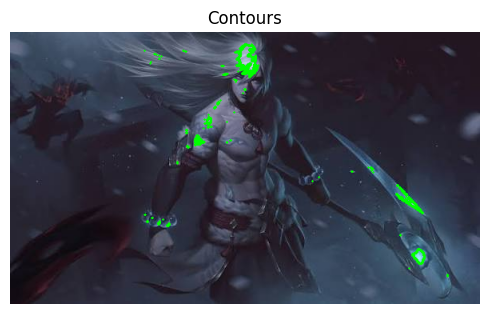

In [6]:
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_NONE)
print("Nombre de contours détectés :", len(contours))

result = img.copy()
cv2.drawContours(result, contours, -1, (0, 255, 0), 2)
show([cv2.cvtColor(result, cv2.COLOR_BGR2RGB)], ["Contours"], cols=1)

### 1.4 Enregistrement du résultat

In [7]:
cv2.imwrite("resultat_contours.jpg", result)

True

## 2. Segmentation d'image

### 2.1 Segmentation par K-Means

**Importation et prétraitement** : reshape de l'image en `(H*W, 3)` puis conversion en `float32`.

In [8]:
img_rgb = cv2.cvtColor(cv2.imread(IMG_PATH), cv2.COLOR_BGR2RGB)
pixels = np.float32(img_rgb.reshape((-1, 3)))
print(img_rgb.shape, "->", pixels.shape)

(340, 588, 3) -> (199920, 3)


**Paramètres** : critères d'arrêt et nombre de clusters K.

In [9]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
K = 3

**Application de K-Means** : `labels` = cluster de chaque pixel, `centers` = couleur de chaque cluster.

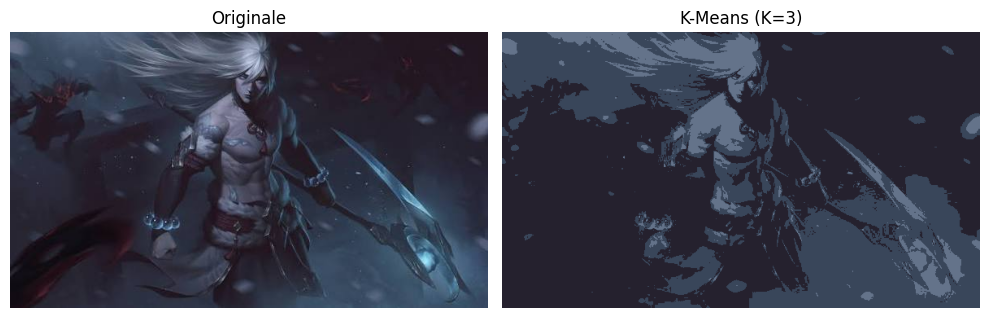

In [10]:
_, labels, centers = cv2.kmeans(pixels, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
centers = np.uint8(centers)
segmented = centers[labels.flatten()].reshape(img_rgb.shape)
show([img_rgb, segmented], ["Originale", f"K-Means (K={K})"], cols=2)

**Résultats pour différentes valeurs de K**

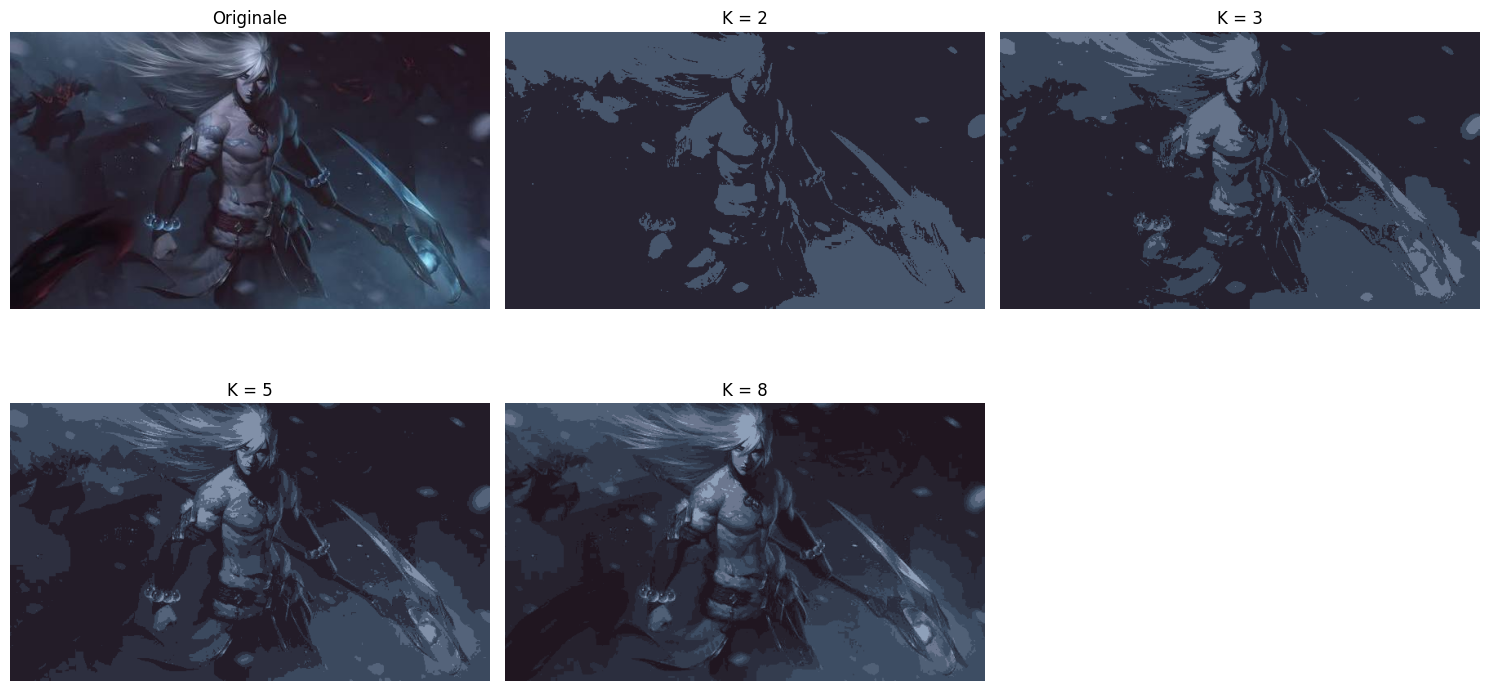

In [11]:
results, titles = [img_rgb], ["Originale"]
for k in (2, 3, 5, 8):
    _, labels, centers = cv2.kmeans(pixels, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    results.append(np.uint8(centers)[labels.flatten()].reshape(img_rgb.shape))
    titles.append(f"K = {k}")
show(results, titles)

### 2.2 Segmentation par détection de contours

**Importation** : l'image est redimensionnée en 512×512 pour créer un masque de même taille.

In [12]:
img2 = cv2.cvtColor(cv2.imread(IMG_PATH), cv2.COLOR_BGR2RGB)
img2 = cv2.resize(img2, (512, 512))

**Seuil** : la valeur du seuil est la moyenne des pixels de l'image en gris.

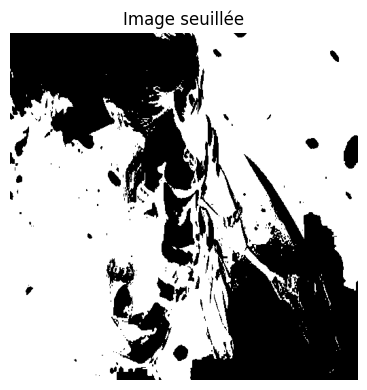

In [13]:
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)
_, thresh2 = cv2.threshold(gray2, gray2.mean(), 255, cv2.THRESH_BINARY_INV)
show([thresh2], ["Image seuillée"], cols=1)

**Détection des bords** : Canny puis dilatation.

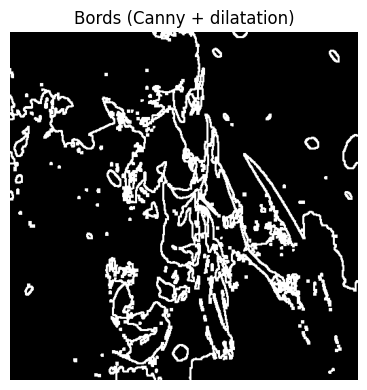

In [14]:
edges = cv2.Canny(thresh2, 100, 200)
edges = cv2.dilate(edges, None, iterations=1)
show([edges], ["Bords (Canny + dilatation)"], cols=1)

**Création du masque** : contours triés par aire décroissante, dessinés sur un masque de zéros.

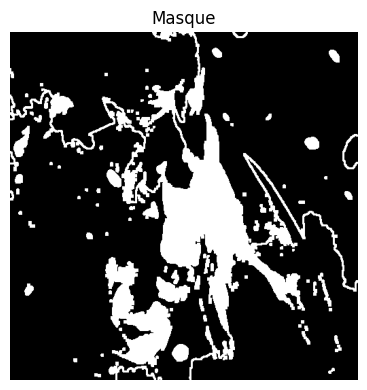

In [16]:
cnt = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]
cnt = sorted(cnt, key=cv2.contourArea, reverse=True)

mask = np.zeros((512, 512), np.uint8)
cv2.drawContours(mask, cnt, -1, 255, -1)
show([mask], ["Masque"], cols=1)

**Segmentation des régions** : ET bit à bit entre l'image et le masque.

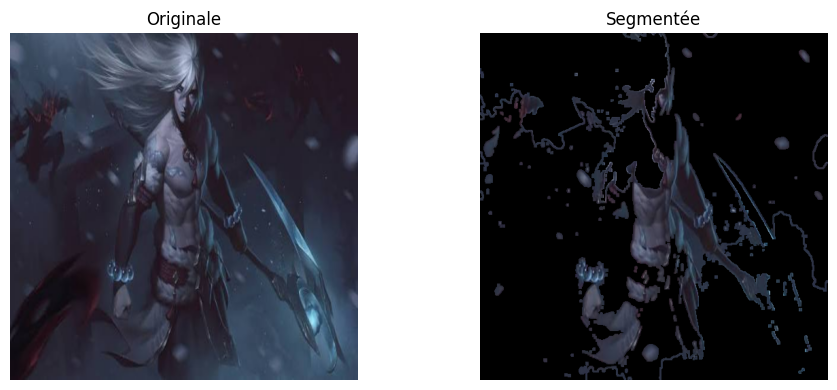

In [17]:
segmented2 = cv2.bitwise_and(img2, img2, mask=mask)
show([img2, segmented2], ["Originale", "Segmentée"], cols=2)

### 2.3 Segmentation par seuil d'Otsu

In [18]:
# !pip install scikit-image
img3 = cv2.cvtColor(cv2.imread(IMG_PATH), cv2.COLOR_BGR2RGB)
gray3 = cv2.cvtColor(img3, cv2.COLOR_RGB2GRAY)

**Seuil d'Otsu** : valeur calculée automatiquement. Inversez la comparaison (`>` / `<`) selon l'image.

Seuil d'Otsu : 62


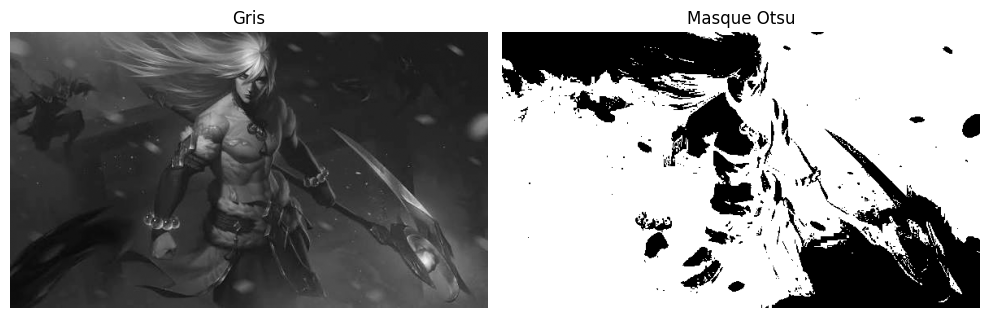

In [19]:
t = threshold_otsu(gray3)
print("Seuil d'Otsu :", t)
img_otsu = (gray3 < t).astype(np.uint8)
show([gray3, img_otsu], ["Gris", "Masque Otsu"], cols=2)

**Processus de segmentation** : `filter_image` multiplie le masque avec chaque canal RVB, puis les concatène.

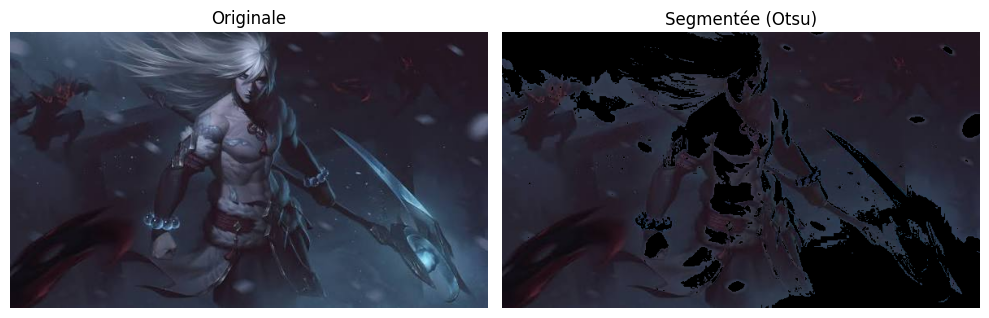

In [20]:
def filter_image(image, mask):
    r, g, b = cv2.split(image)
    return cv2.merge([r * mask, g * mask, b * mask])

segmented3 = filter_image(img3, img_otsu)
show([img3, segmented3], ["Originale", "Segmentée (Otsu)"], cols=2)

### 2.4 Segmentation par masquage de couleur

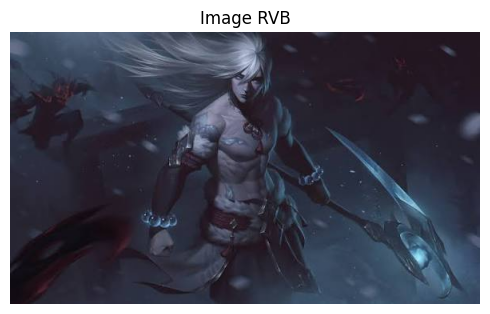

In [21]:
img4 = cv2.imread(IMG_PATH)
img4 = cv2.cvtColor(img4, cv2.COLOR_BGR2RGB)  # BGR -> RGB
show([img4], ["Image RVB"], cols=1)

**Masque par détection de couleur** : `inRange()` avec plages RVB basse et haute (ici vert, à adapter à votre image).

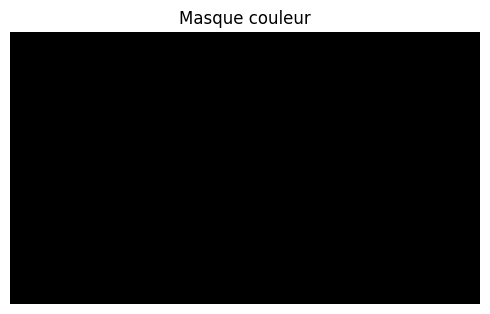

In [22]:
low = np.array([0, 100, 0])
high = np.array([100, 255, 100])
mask4 = cv2.inRange(img4, low, high)
show([mask4], ["Masque couleur"], cols=1)

**Application du masque** : opération `bitwise_and`.

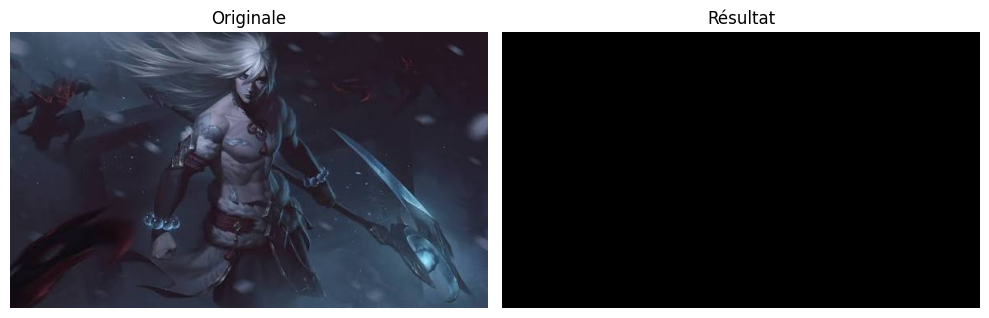

In [23]:
result4 = cv2.bitwise_and(img4, img4, mask=mask4)
show([img4, result4], ["Originale", "Résultat"], cols=2)